# Modelagem preditiva e avaliação de classificadores (Atividade_Formativa.ipynb)

- **Repositório:** `machine-learning-portfolio`  
- **Tecnologias:** Scikit-Learn  
- **Arquivo Original:** `Atividade_Formativa.ipynb`  

---


In [1]:
# Carregando recursos necessários
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_predict, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn import datasets
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
import sklearn.model_selection as model_selection
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
import xgboost as xgb
from sklearn.datasets import load_breast_cancer

from warnings import simplefilter
simplefilter(action='ignore', category=FutureWarning)

In [2]:
import pandas as pd
import numpy as np
# loading attribute names
att=pd.read_csv('glass.csv', index_col=-1, nrows=0).columns.tolist()
print(att)
# loading the data
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:,0:9]
y = dataset[:,9]
print(X.shape)

# Dividindo os dados em conjuntos de treino e validação
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
(214, 9)


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py:540: FitFailedWarning: 
2600 fits failed out of a total of 31200.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1300 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 1473, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py", line 238, in fit
    return self._fit(X, y)
  File "/usr/local/lib/python3.10/dist-p

Melhores parâmetros para KNN: {'algorithm': 'auto', 'leaf_size': 20, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': -1, 'n_neighbors': 1, 'p': 1, 'weights': 'uniform'}
Melhor acurácia no GridSearch KNN: 0.747
F1 Score do KNN: 0.681
Matriz de Confusão


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_search.py:1103: UserWarning: One or more of the test scores are non-finite: [0.74678854 0.74678854 0.74315621 ... 0.55504564 0.50901171 0.55504564]
  warnings.warn(


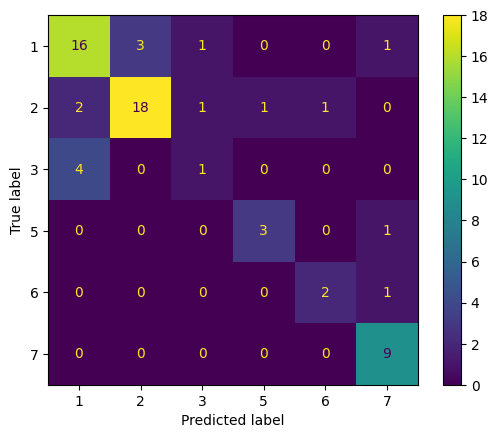

In [3]:
# Definindo o classificador KNN
knn = KNeighborsClassifier()

# Definindo os hiperparâmetros para o GridSearch
knn_param = {
    'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 25],  # Adicionado mais valores para vizinhos
    'weights': ['uniform', 'distance'],
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
    'metric': ['minkowski', 'euclidean', 'manhattan', 'chebyshev', 'hamming', 'canberra'],  # Adicionado novas métricas de distância
    'leaf_size': [20, 30, 40, 50, 60],  # Adicionado mais valores para leaf_size
    'p': [1, 2],
    'n_jobs': [-1],  # Usar todos os núcleos disponíveis para acelerar
    'metric_params': [None],  # Parâmetros adicionais para a métrica (pode incluir parâmetros específicos)
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],  # Manteve as opções anteriores para algoritmos
}



# Realizando o GridSearch no KNN
knn_grid = GridSearchCV(knn, knn_param, scoring='f1_weighted', cv=5)
knn_grid.fit(X_train, y_train)

y_pred = knn_grid.predict(X_val)


f1_knn = f1_score(y_val, knn_grid.predict(X_val), average='macro')

# Exibindo os melhores parâmetros encontrados para o KNN
print("Melhores parâmetros para KNN:", knn_grid.best_params_)
print("Melhor acurácia no GridSearch KNN: %.3f" % knn_grid.best_score_)
print("F1 Score do KNN: %.3f" % f1_knn)

print("Matriz de Confusão")
# The confusion matrix should be calculated using the validation set labels (y_val) and predictions (y_pred)
matrix=confusion_matrix(y_val, y_pred)
#print(matrix)
disp=ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=[1,2,3,5,6,7])
disp.plot()

Melhores parâmetros para DT: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 30, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.01, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'random'}
Melhor acurácia no GridSearch DT: 0.727
F1 Score do DT: 0.756
Matriz de Confusão


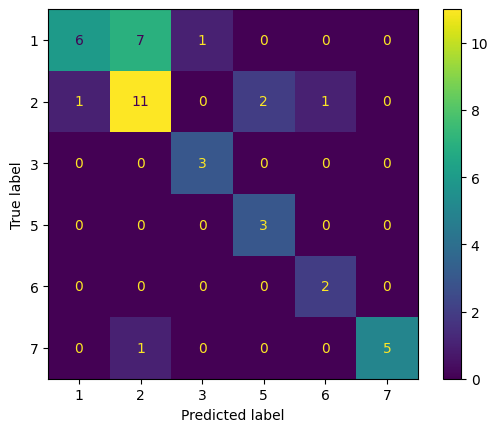

In [ ]:
# Definindo o classificador KNN
dt = DecisionTreeClassifier()

# Definindo os hiperparâmetros para o GridSearch
dt_param = {
    'criterion': ['gini', 'entropy', 'log_loss'],  # Função de medida para divisão
    'splitter': ['best', 'random'],                # Estratégia de divisão nos nós
    'max_depth': [None, 10, 20, 30, 40, 50],       # Profundidade máxima da árvore
    'min_samples_split': [2, 5, 10],               # Número mínimo de amostras para dividir um nó
    'min_samples_leaf': [1, 2, 4],                 # Número mínimo de amostras em um nó folha
    'max_leaf_nodes': [None, 10, 20, 30],          # Número máximo de nós folha
    'min_impurity_decrease': [0.0, 0.01, 0.1],     # Redução mínima na impureza para dividir um nó
    'class_weight': [None, 'balanced'],            # Ajuste de peso das classes
}




# Realizando o GridSearch no KNN
dt_grid = GridSearchCV(dt, dt_param, scoring='f1_weighted', cv=5)
dt_grid.fit(X_train, y_train)

y_pred = dt_grid.predict(X_val)


f1_dt = f1_score(y_val, dt_grid.predict(X_val), average='macro')

# Exibindo os melhores parâmetros encontrados para o KNN
print("Melhores parâmetros para DT:", dt_grid.best_params_)
print("Melhor acurácia no GridSearch DT: %.3f" % dt_grid.best_score_)
print("F1 Score do DT: %.3f" % f1_dt)

print("Matriz de Confusão")
# The confusion matrix should be calculated using the validation set labels (y_val) and predictions (y_pred)
matrix=confusion_matrix(y_val, y_pred)
#print(matrix)
disp=ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=[1,2,3,5,6,7])
disp.plot()

/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Acurácia média: 0.648
Desvio padrão: 0.045


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


f1: 0.570
Melhores parâmetros para Bagging: {'estimator': KNeighborsClassifier(leaf_size=20, n_jobs=-1, n_neighbors=1, p=1), 'max_samples': 1.0, 'n_estimators': 30}
Melhor estimador: BaggingClassifier(estimator=KNeighborsClassifier(leaf_size=20, n_jobs=-1,
                                                 n_neighbors=1, p=1),
                  n_estimators=30, random_state=42)
Matriz de Confusão


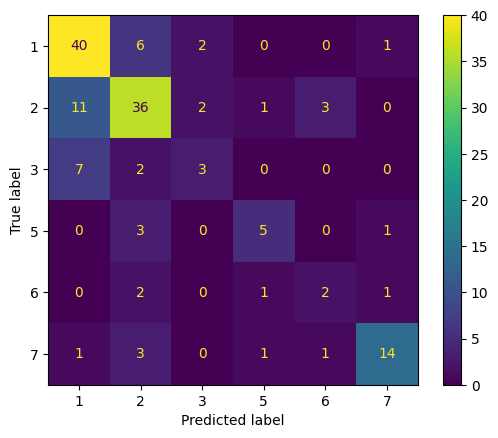

In [ ]:
# Definindo classificadores de base (estimators)
dt_final =  DecisionTreeClassifier(class_weight= 'balanced',
                             criterion= 'entropy',
                             max_depth= None,
                             max_leaf_nodes= None,
                             min_impurity_decrease= 0.0,
                             min_samples_leaf= 1,
                             min_samples_split= 2,
                             splitter= 'random')

knn_final = KNeighborsClassifier(algorithm= 'auto',
                           leaf_size= 20,
                           metric= 'minkowski',
                           metric_params= None,
                           n_jobs= -1,
                           n_neighbors= 1,
                           p= 1,
                           weights= 'uniform')

# Instanciando o Bagging
bg = BaggingClassifier(random_state=42)

# Definindo os parâmetros para o GridSearch
bag_param = [{'estimator': [dt_final, knn_final],
              'n_estimators': [10, 30],
              'max_samples': [0.5, 0.7, 1.0]}]

# Instanciando o GridSearch
clf = GridSearchCV(bg, bag_param, scoring='f1_weighted', cv=5)

# Ajustando o modelo com os dados
clf.fit(X_train, y_train)  # Ajustar o modelo com todos os dados

# Usando validação cruzada com T=5 folds
result = cross_val_score(clf, X_train, y_train, cv=5)
print("Acurácia média: %.3f" % result.mean())
print("Desvio padrão: %.3f" % result.std())

# Calculando a predição para cada exemplo de teste
y_pred = cross_val_predict(clf, X_train, y_train, cv=5)

# Calcular f1 score
f1 = f1_score(y_train, y_pred, average='macro')
print("f1: %.3f" % f1)

# Acessando os melhores parâmetros
print("Melhores parâmetros para Bagging:", clf.best_params_)
print("Melhor estimador:", clf.best_estimator_)

# Matriz de Confusão
print("Matriz de Confusão")
matrix = confusion_matrix(y_train, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=[1, 2, 3, 5, 6, 7])
disp.plot()

Acurácia média: 0.956
Desvio padrão: 0.017
f1: 0.953
Matriz de Confusão


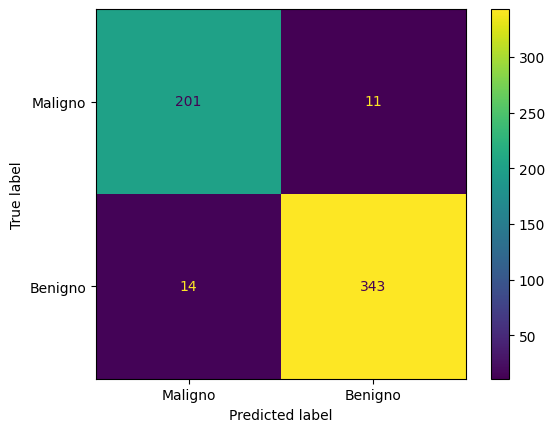

In [ ]:
# Exemplo: uso de Bagging e GridSearch()
# Carregando a base de dados
X,y=load_breast_cancer(return_X_y=True)

# Definindo classificadores de base (estimators)
dt =  DecisionTreeClassifier(criterion='entropy')
knn = KNeighborsClassifier(n_neighbors=3, weights='distance')

# Instanciando o Bagging
bg = BaggingClassifier(random_state=42)

# Caso queira usar Gridsearch, segue exemplo
# Retirando 20% da base para o GridSearch
# Obs: há mais hiperparâmetros do Bagging que poderiam ser explorados neste caso, segue exemplo abaixo:
bag_param = [{'estimator': [dt, knn],'n_estimators': [10, 30], 'max_samples': [0.5, 0.7, 1.0]}]
clf = GridSearchCV(bg, bag_param, scoring = 'accuracy', cv=5)

# Usando validação cruzada com T=5 folds
result=model_selection.cross_val_score(clf, X, y, cv=5)
print("Acurácia média: %.3f" % result.mean())
print("Desvio padrão: %.3f" % result.std())

# Calculando a predição para cada exempolo de teste
y_pred=model_selection.cross_val_predict(clf, X, y, cv=5)

# Calcular f1 score
f1=f1_score(y, y_pred, average='macro')
print("f1: %.3f" % f1)

print("Matriz de Confusão")
matrix=confusion_matrix(y, y_pred)
#print(matrix)
disp=ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=['Maligno', 'Benigno'])
disp.plot()




Acurácia média: 0.974
Desvio padrão: 0.015
f1: 0.972
Matriz de Confusão


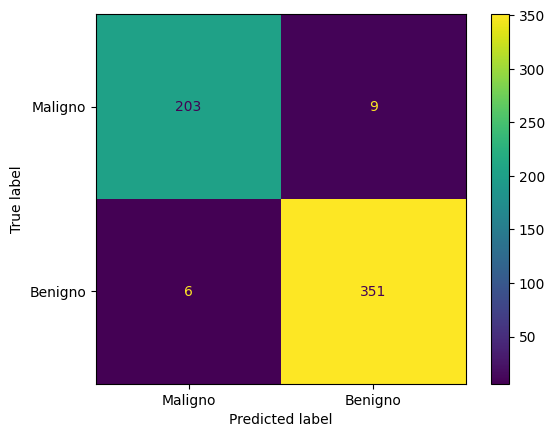

In [ ]:
# Exemplo de outros Algoritmos de ensembles homogêneos (AdaBoost, XGBoost e Random Forest).
# Agora sem uso do GridSearch. Dá para usar GridSearch claro, mas aqui optamos por nao.
# Carregando a base de dados
X,y=load_breast_cancer(return_X_y=True)

# Instanciado a técnica escolhida
# clf = AdaBoostClassifier(n_estimators=100, random_state=42)
xgboost = xgb.XGBClassifier(objective="binary:logistic", random_state=42)
#rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Usando validação cruzada com T=5 folds
result=model_selection.cross_val_score(clf, X, y, cv=5)
print("Acurácia média: %.3f" % result.mean())
print("Desvio padrão: %.3f" % result.std())

# Calculando a predição para cada exempolo de teste
y_pred=model_selection.cross_val_predict(clf, X, y, cv=5)

# Calcular f1 score
f1=f1_score(y, y_pred, average='macro')
print("f1: %.3f" % f1)

print("Matriz de Confusão")
matrix=confusion_matrix(y, y_pred)
#print(matrix)
disp=ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=['Maligno', 'Benigno'])
disp.plot()



